# P2 Build a codec

# Huffman codec implementation

In [8]:
import heapq
from collections import Counter
import json
import numpy as np

class Node:
	def __init__(self, symbol=None, frequency=None, order=0):
		self.symbol = symbol
		self.frequency = frequency
		self.order = order
		self.left = None
		self.right = None
	def __lt__(self, other):
		if self.frequency != other.frequency:
			return self.frequency < other.frequency
		return self.order < other.order

def build_huffman_tree(counts):
	heap = []

	for order, (sym, f) in enumerate(sorted(counts.items())):
		heapq.heappush(heap, Node(sym, f, order))

	order = len(heap)

	while len(heap) > 1:
		left = heapq.heappop(heap)
		right = heapq.heappop(heap)
		merged = Node(frequency=left.frequency + right.frequency, order = order)
		merged.left = left
		merged.right = right
		heapq.heappush(heap, merged)

	return heap[0]

def get_code_lengths_from_tree(root):
	lengths = {}

	def walk(node, depth=0):
		if node.symbol is not None:
			lengths[node.symbol] = depth
		else:
			walk(node.left, depth + 1)
			walk(node.right, depth + 1)

	walk(root)

	if len(lengths) == 1:
		lengths[next(iter(lengths))] = 1

	return lengths

def huffman_lengths(counts):
	if not counts:
		return {}

	root = build_huffman_tree(counts)
	return get_code_lengths_from_tree(root)

def canonical_codes(lengths):
	present = sorted(lengths, key=lambda s: (lengths[s], s))
	codes = {}
	code = 0
	prev_len = 0

	for s in present:
		L = lengths[s]
		code <<= (L - prev_len)
		codes[s] = f"{code:0{L}b}"
		code += 1
		prev_len = L

	return codes

# Byte compression/decompression and header parser

In [9]:
MAGIC_BYTES = b"HC\x01"  # used by a series of bytes
MAGIC_ARRAY = b"HC\x02H" # used by numpy arrays

BASE_HEADER_BYTES = 13

def compress_bytes(data):
	if not isinstance(data, (bytes, bytearray)):
		raise TypeError("compress_bytes expects bytes")

	data = bytes(data)

	if not data:
		return MAGIC_BYTES + (0).to_bytes(8, "big") + (0).to_bytes(2, "big")

	freq = Counter(data)
	lengths = huffman_lengths(freq)
	codes = canonical_codes(lengths)

	present = sorted(freq)
	header = bytearray(MAGIC_BYTES)             
	header += len(data).to_bytes(8, "big")    
	header += len(present).to_bytes(2, "big")

	for s in present:
		header.append(s)
		header.append(lengths[s])
		
	bitstring = "".join(codes[b] for b in data)
	nbits = len(bitstring)
	payload = int(bitstring + "0" * (-nbits % 8), 2).to_bytes((nbits + 7) // 8, "big") if nbits else b""
	
	return bytes(header) + payload

def parse_header(compressed):
	compressed = bytes(compressed)

	if len(compressed) < BASE_HEADER_BYTES or compressed[:3] != MAGIC_BYTES:
		raise ValueError("bad header: wrong magic or stream too short")

	orig_len = int.from_bytes(compressed[3:11], "big")
	nums_syms = int.from_bytes(compressed[11:13], "big")

	pos = BASE_HEADER_BYTES
	present = []
	lengths = {}

	for _ in range(nums_syms):
		s = compressed[pos]
		l = compressed[pos + 1]

		if l == 0:
			raise ValueError(f"bad code length 0 for symbol {s}")

		if s in lengths:
			raise ValueError(f"duplicate symbol {s} in table")

		present.append(s)
		lengths[s] = l
		pos += 2

	return orig_len, present, lengths, pos

def decompress_bytes(compressed):
	orig_len, _, lengths, pos = parse_header(compressed)

	if orig_len == 0:
		return b""

	codes = canonical_codes(lengths)
	decoded_table = {code: sym for sym, code in codes.items()}

	out = bytearray()
	current = ""

	for byte in compressed[pos:]:
		for i in range(7, -1, -1):
			current += "1" if byte & (1 << i) else "0"

			if current in decoded_table:
				out.append(decoded_table[current])
				current = ""

				if len(out) == orig_len:
					return bytes(out)

	raise ValueError("truncated bitstream")

# Seperating header and bytes

In [10]:
from functools import lru_cache

PREDICTORS = (
    "none",
    "horizontal_delta",
    "vertical_delta",
    "spiral_delta",
    "auto",
)

@lru_cache(maxsize=None)
def spiral_order(h, w):
    top, bottom, left, right = 0, h - 1, 0, w - 1
    idx = []

    while top <= bottom and left <= right:
        for x in range(left, right + 1):
            idx.append(top * w + x)

        for y in range(top + 1, bottom + 1):
            idx.append(y * w + right)

        if bottom > top:
            for x in range(right - 1, left - 1, -1):
                idx.append(bottom * w + x)

        if right > left and bottom > top:
            for y in range(bottom - 1, top, -1):
                idx.append(y * w + left)

        top += 1
        bottom -= 1
        left += 1
        right -= 1

    assert len(idx) == h * w
    order = np.array(idx, dtype=np.int64)
    order.setflags(write=False)
    return order


def is_valid(arr):
    return (
        isinstance(arr, np.ndarray)
        and arr.dtype == np.uint8
        and arr.ndim == 3
        and arr.shape[2] == 3
    )


def preprocess_delta(arr, direction="horizontal"):
    if arr.size == 0:
        return arr.copy()

    if not is_valid(arr):
        raise ValueError(
            f"Delta predictor needs uint8 HxWx3, "
            f"got {arr.dtype} {arr.shape}"
        )

    if direction == "horizontal":
        residual = np.empty_like(arr)
        residual[:, 0, :] = arr[:, 0, :]
        residual[:, 1:, :] = (
            arr[:, 1:, :].astype(np.int16)
            - arr[:, :-1, :].astype(np.int16)
        ) % 256

    elif direction == "vertical":
        residual = np.empty_like(arr)
        residual[0, :, :] = arr[0, :, :]
        residual[1:, :, :] = (
            arr[1:, :, :].astype(np.int16)
            - arr[:-1, :, :].astype(np.int16)
        ) % 256

    elif direction == "spiral":
        h, w, _ = arr.shape
        order = spiral_order(h, w)
        along = arr.reshape(-1, 3)[order]

        residual = np.empty_like(along)
        residual[0] = along[0]
        residual[1:] = (
            along[1:].astype(np.int16)
            - along[:-1].astype(np.int16)
        ) % 256

        out = np.empty((h * w, 3), dtype=np.uint8)
        out[order] = residual
        residual = out.reshape(h, w, 3)

    else:
        raise ValueError(f"Unknown predictor direction: {direction}")

    return residual.astype(np.uint8)


def postprocess_delta(residual, direction="horizontal"):
    if residual.size == 0:
        return residual.astype(np.uint8)

    recon = np.empty_like(residual)

    if direction == "horizontal":
        recon[:, 0, :] = residual[:, 0, :]
        for x in range(1, residual.shape[1]):
            recon[:, x, :] = (
                residual[:, x, :].astype(np.int16)
                + recon[:, x - 1, :].astype(np.int16)
            ) % 256

    elif direction == "vertical":
        recon[0, :, :] = residual[0, :, :]
        for y in range(1, residual.shape[0]):
            recon[y, :, :] = (
                residual[y, :, :].astype(np.int16)
                + recon[y - 1, :, :].astype(np.int16)
            ) % 256

    elif direction == "spiral":
        h, w, _ = residual.shape
        order = spiral_order(h, w)
        along = residual.reshape(-1, 3)[order]

        rec = np.cumsum(along.astype(np.int64), axis=0) % 256

        out = np.empty((h * w, 3), dtype=np.uint8)
        out[order] = rec
        recon = out.reshape(h, w, 3)

    else:
        raise ValueError(f"Unknown predictor direction: {direction}")

    return recon.astype(np.uint8)


def encode_with_predictor(arr, predictor):
    if predictor != "none" and not is_valid(arr):
        predictor = "none"

    if predictor == "horizontal_delta":
        encoded_arr = preprocess_delta(arr, "horizontal")
    elif predictor == "vertical_delta":
        encoded_arr = preprocess_delta(arr, "vertical")
    elif predictor == "spiral_delta":
        encoded_arr = preprocess_delta(arr, "spiral")
    else:
        encoded_arr = arr

    meta = {
        "shape": list(arr.shape),
        "dtype": str(arr.dtype),
        "predictor": predictor,
    }
    meta_bytes = json.dumps(
        meta, separators=(",", ":")
    ).encode("utf-8")

    if len(meta_bytes) > 0xFFFFFFFF:
        raise ValueError("Array metadata is too large")

    raw_bytes = np.ascontiguousarray(encoded_arr).tobytes()
    payload = compress_bytes(raw_bytes)

    return (
        MAGIC_ARRAY
        + len(meta_bytes).to_bytes(4, "big")
        + meta_bytes
        + payload
    )


def compress_array(arr, settings=None):
    if not isinstance(arr, np.ndarray):
        raise TypeError("compress_array expects a np.ndarray")

    settings = settings or {}
    predictor = settings.get("predictor", "auto")

    if predictor not in PREDICTORS:
        raise ValueError(f"Unknown predictor: {predictor}. Valid: {PREDICTORS}")

    if predictor == "auto":
        if not is_valid(arr):
            return encode_with_predictor(arr, "none")

        candidates = (
            encode_with_predictor(arr, "none"),
            encode_with_predictor(arr, "spiral_delta"),
            encode_with_predictor(arr, "vertical_delta"),
            encode_with_predictor(arr, "horizontal_delta"),
        )

        return min(candidates, key=len)

    return encode_with_predictor(arr, predictor)


def decompress_array(compressed):
    if len(compressed) < 4:
        raise ValueError("Truncated array header")

    meta_len = int.from_bytes(compressed[:4], "big")
    meta_end = 4 + meta_len

    if meta_end > len(compressed):
        raise ValueError("Truncated array metadata")

    try:
        meta = json.loads(compressed[4:meta_end].decode("utf-8"))
        shape = tuple(meta["shape"])
        dtype = np.dtype(meta["dtype"])
        predictor = meta["predictor"]
    except (UnicodeDecodeError, json.JSONDecodeError, KeyError,
            TypeError, ValueError) as exc:
        raise ValueError("Invalid array metadata") from exc

    if predictor not in PREDICTORS or predictor == "auto":
        raise ValueError(f"Invalid stored predictor: {predictor}")

    if any(not isinstance(d, int) or d < 0 for d in shape):
        raise ValueError("Invalid array shape")

    raw_bytes = decompress_bytes(compressed[meta_end:])

    expected_nbytes = int(np.prod(shape, dtype=object)) * dtype.itemsize
    if len(raw_bytes) != expected_nbytes:
        raise ValueError(
            f"Decoded byte count mismatch: expected {expected_nbytes}, "
            f"got {len(raw_bytes)}"
        )

    arr = np.frombuffer(raw_bytes, dtype=dtype).copy().reshape(shape)

    if predictor != "none":
        if not is_valid(arr):
            raise ValueError("Stored predictor is incompatible with array")

        direction = {
            "horizontal_delta": "horizontal",
            "vertical_delta": "vertical",
            "spiral_delta": "spiral",
        }[predictor]

        arr = postprocess_delta(arr, direction)

    return arr


# Compress and decompress interface

In [11]:
def compress(data, settings=None):
	if isinstance(data, np.ndarray):
		return compress_array(data, settings)
	return compress_bytes(data)

def decompress(compressed):
	if compressed[:len(MAGIC_ARRAY)] == MAGIC_ARRAY:
		return decompress_array(compressed[4:])
	if compressed[:len(MAGIC_BYTES)] == MAGIC_BYTES:
		return decompress_bytes(compressed)
	raise ValueError("unknown format: " + repr(compressed[:4]))

# Roundtrip test cases for raw bytes and numpy arrays

In [12]:
rng = np.random.default_rng(4120)

def check_roundtrip(data, name, settings=None):
    n_in = data.nbytes if isinstance(data, np.ndarray) else len(data)

    compressed = compress(data, settings)
    reconstructed = decompress(compressed)

    if isinstance(data, np.ndarray):
        assert isinstance(reconstructed, np.ndarray), f"{name}: not an ndarray"
        assert reconstructed.shape == data.shape, f"{name}: shape changed"
        assert reconstructed.dtype == data.dtype, f"{name}: dtype changed"
        np.testing.assert_array_equal(reconstructed, data, err_msg=name)
    else:
        assert reconstructed == data, f"{name}: bytes differ"

    print(f"{name:34s} {n_in:>9,} B -> {len(compressed):>9,} B   PASS")

gradient = np.tile(np.arange(256, dtype=np.uint8), (16, 2))[:, :, None] * np.ones(3, np.uint8)

byte_cases = [
    ("empty bytes",           b""),
    ("single byte",           b"\x00"),
    ("single byte 0xff",      b"\xff"),
    ("two bytes",             b"ab"),
    ("one repeated symbol",   b"q" * 1_000),
    ("all 256 symbols once",  bytes(range(256))),
    ("all 256 symbols x40",   bytes(range(256)) * 40),
    ("random bytes, 100 KB",  bytes(rng.integers(0, 256, 100_000, dtype=np.uint8))),
    ("text-like, skewed",     b"the quick brown fox jumps " * 400),
]

array_cases = [
    ("empty 1-D uint8",                  np.zeros(0, dtype=np.uint8)),
    ("empty image (0, 4, 3)",            np.zeros((0, 4, 3), dtype=np.uint8)),
    ("single pixel",                     rng.integers(0, 256, (1, 1, 3), dtype=np.uint8)),
    ("tiny image (2, 3, 3)",            rng.integers(0, 256, (2, 3, 3), dtype=np.uint8)),
    ("constant image (1 symbol)",        np.full((8, 8, 3), 7, dtype=np.uint8)),
    ("horizontal gradient (delta path)", gradient),
    ("random image (64, 64, 3)",         rng.integers(0, 256, (64, 64, 3), dtype=np.uint8)),
    ("grayscale 2-D (no predictor)",     rng.integers(0, 256, (10, 10), dtype=np.uint8)),
    ("int16 1-D",                       np.arange(-5, 5, dtype=np.int16)),
    ("float32 2-D",                     rng.random((4, 5), dtype=np.float32)),
]

for name, data in byte_cases + array_cases:
    check_roundtrip(data, name)

empty bytes                                0 B ->        13 B   PASS
single byte                                1 B ->        16 B   PASS
single byte 0xff                           1 B ->        16 B   PASS
two bytes                                  2 B ->        18 B   PASS
one repeated symbol                    1,000 B ->       140 B   PASS
all 256 symbols once                     256 B ->       781 B   PASS
all 256 symbols x40                   10,240 B ->    10,765 B   PASS
random bytes, 100 KB                 100,000 B ->   100,525 B   PASS
text-like, skewed                     10,400 B ->     5,453 B   PASS
empty 1-D uint8                            0 B ->        69 B   PASS
empty image (0, 4, 3)                      0 B ->        73 B   PASS
single pixel                               3 B ->        80 B   PASS
tiny image (2, 3, 3)                      18 B ->       117 B   PASS
constant image (1 symbol)                192 B ->        99 B   PASS
horizontal gradient (delta path)  

# Image roundtrip tests

In [13]:
# settings knob works in both directions
img = rng.integers(0, 256, (16, 16, 3), dtype=np.uint8)
check_roundtrip(img, "predictor horizontal delta",  settings={"predictor": "horizontal_delta"})
check_roundtrip(img, "predictor vertical delta",  settings={"predictor": "vertical_delta"})
check_roundtrip(img, "predictor sprial delta", settings={"predictor": "spiral_delta"})
check_roundtrip(img, "predictor forced off", settings={"predictor": "none"})
check_roundtrip(img, "predictor forced auto", settings={"predictor": "auto"})

# the unseen file (image of a man)
from PIL import Image
unseen = np.asarray(Image.open("unseen.png").convert("RGB"), dtype=np.uint8)
check_roundtrip(unseen, "unseen file (auto)")
check_roundtrip(unseen, "unseen file (none)", settings={"predictor": "none"})
check_roundtrip(unseen, "unseen file (horizontal delta)", settings={"predictor": "horizontal_delta"})
check_roundtrip(unseen, "unseen file (vertical delta)", settings={"predictor": "vertical_delta"})
check_roundtrip(unseen, "unseen file (spiral delta)", settings={"predictor": "spiral_delta"})

# the unseen2 file (image of noise)
unseen = np.asarray(Image.open("unseen2.png").convert("RGB"), dtype=np.uint8)
check_roundtrip(unseen, "unseen 2 file (auto)")
check_roundtrip(unseen, "unseen 2 file (none)", settings={"predictor": "none"})
check_roundtrip(unseen, "unseen 2 file (horizontal delta)", settings={"predictor": "horizontal_delta"})
check_roundtrip(unseen, "unseen 2 file (vertical delta)", settings={"predictor": "vertical_delta"})
check_roundtrip(unseen, "unseen 2 file (spiral delta)", settings={"predictor": "spiral_delta"})

predictor horizontal delta               768 B ->     1,304 B   PASS
predictor vertical delta                 768 B ->     1,329 B   PASS
predictor sprial delta                   768 B ->     1,323 B   PASS
predictor forced off                     768 B ->     1,319 B   PASS
predictor forced auto                    768 B ->     1,304 B   PASS
unseen file (auto)                   583,200 B ->   146,410 B   PASS
unseen file (none)                   583,200 B ->   219,106 B   PASS
unseen file (horizontal delta)       583,200 B ->   160,280 B   PASS
unseen file (vertical delta)         583,200 B ->   146,410 B   PASS
unseen file (spiral delta)           583,200 B ->   148,543 B   PASS
unseen 2 file (auto)                  88,800 B ->    87,001 B   PASS
unseen 2 file (none)                  88,800 B ->    87,001 B   PASS
unseen 2 file (horizontal delta)      88,800 B ->    89,301 B   PASS
unseen 2 file (vertical delta)        88,800 B ->    89,280 B   PASS
unseen 2 file (spiral delta)      

# Image loader and reported byte count

kirmizi (1).jpg
  raw:         1,080,000 bytes
  compressed:    230,647 bytes (4.68x, 5.13 bits/pixel, predictor=vertical_delta)
  side info:         599 bytes (marker 4 + length field 4 + JSON metadata 66 + Huffman header 13 + symbol table 512)
  payload:       230,048 bytes (Huffman-coded data)
  PNG baseline (lossless): 94,867 bytes
  JPEG baseline, quality=95 (lossy): 31,199 bytes
  Original JPEG on disk: 22,307 bytes


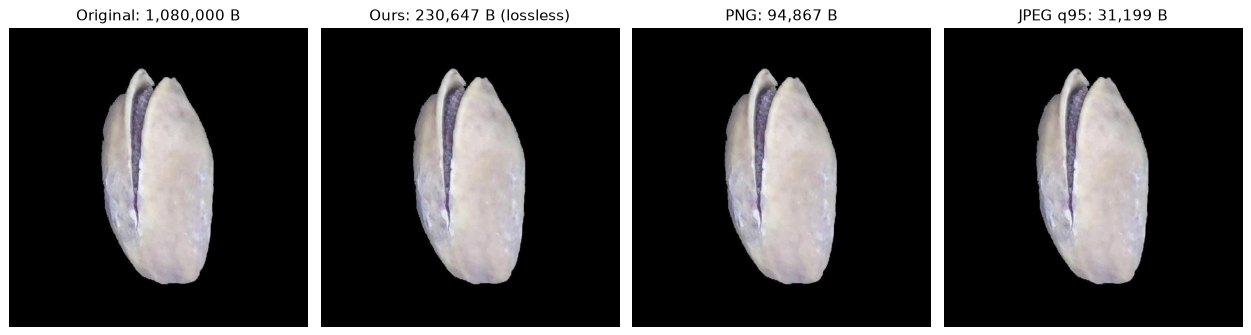

kirmizi (10).jpg
  raw:         1,080,000 bytes
  compressed:    221,718 bytes (4.87x, 4.93 bits/pixel, predictor=vertical_delta)
  side info:         599 bytes (marker 4 + length field 4 + JSON metadata 66 + Huffman header 13 + symbol table 512)
  payload:       221,119 bytes (Huffman-coded data)
  PNG baseline (lossless): 97,616 bytes
  JPEG baseline, quality=95 (lossy): 32,024 bytes
  Original JPEG on disk: 22,099 bytes


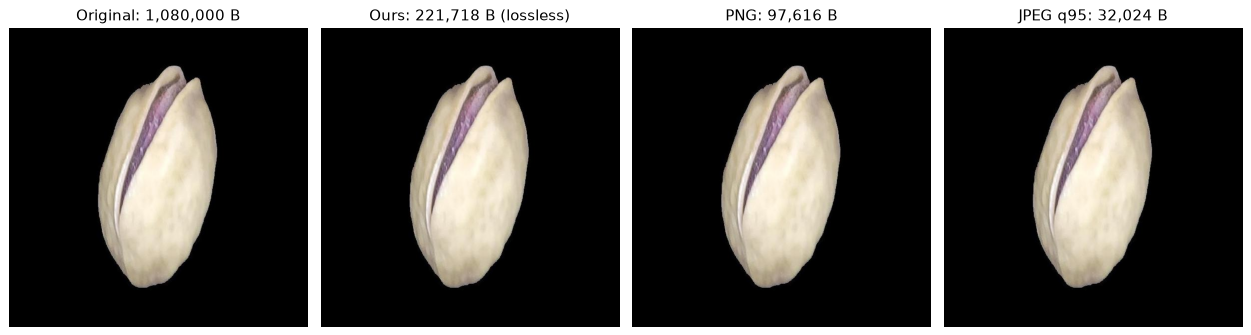

kirmizi (11).jpg
  raw:         1,080,000 bytes
  compressed:    241,131 bytes (4.48x, 5.36 bits/pixel, predictor=vertical_delta)
  side info:         599 bytes (marker 4 + length field 4 + JSON metadata 66 + Huffman header 13 + symbol table 512)
  payload:       240,532 bytes (Huffman-coded data)
  PNG baseline (lossless): 114,154 bytes
  JPEG baseline, quality=95 (lossy): 35,652 bytes
  Original JPEG on disk: 23,747 bytes


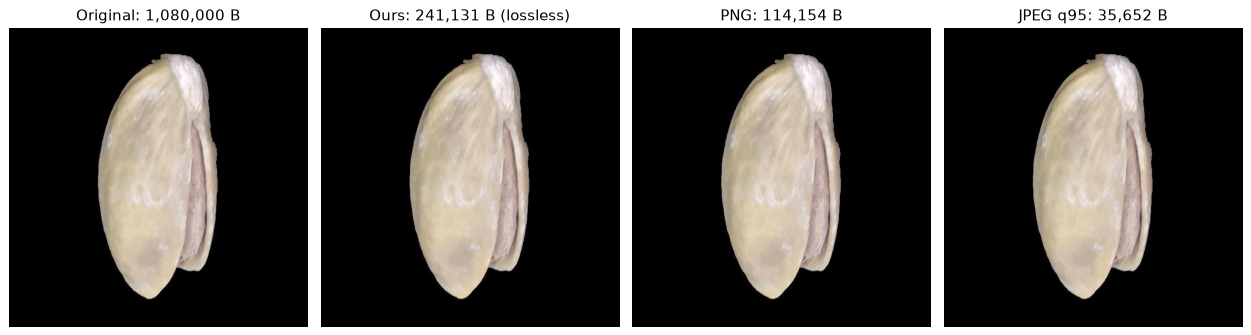

kirmizi (12).jpg
  raw:         1,080,000 bytes
  compressed:    212,245 bytes (5.09x, 4.72 bits/pixel, predictor=vertical_delta)
  side info:         599 bytes (marker 4 + length field 4 + JSON metadata 66 + Huffman header 13 + symbol table 512)
  payload:       211,646 bytes (Huffman-coded data)
  PNG baseline (lossless): 81,907 bytes
  JPEG baseline, quality=95 (lossy): 29,691 bytes
  Original JPEG on disk: 21,473 bytes


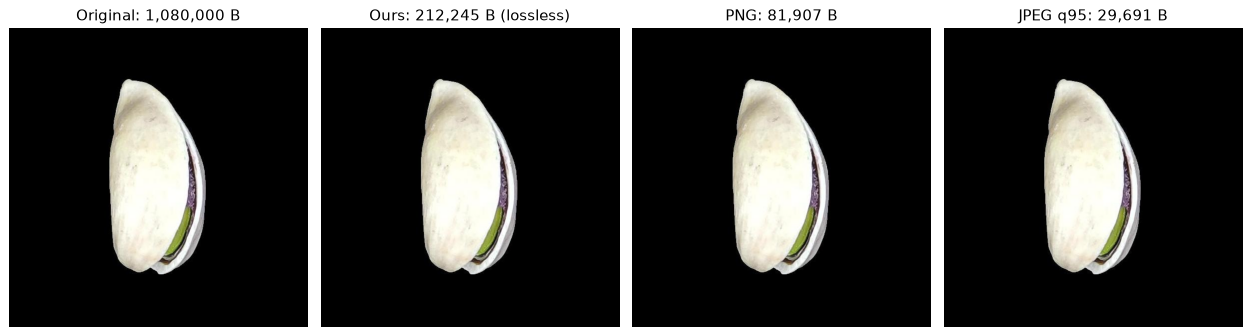

kirmizi (13).jpg
  raw:         1,080,000 bytes
  compressed:    234,973 bytes (4.60x, 5.22 bits/pixel, predictor=vertical_delta)
  side info:         599 bytes (marker 4 + length field 4 + JSON metadata 66 + Huffman header 13 + symbol table 512)
  payload:       234,374 bytes (Huffman-coded data)
  PNG baseline (lossless): 105,618 bytes
  JPEG baseline, quality=95 (lossy): 34,772 bytes
  Original JPEG on disk: 23,371 bytes


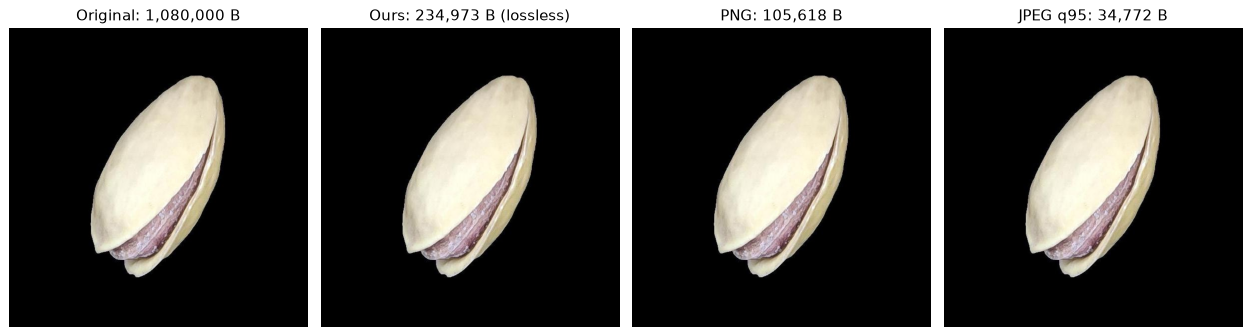

In [14]:
from pathlib import Path
from PIL import Image
import io
import matplotlib.pyplot as plt

RESOURCE_DIR_KIRMIZI = Path("dataset/Pistachio_Image_Dataset/Pistachio_Image_Dataset/Kirmizi_Pistachio")

def load_images(folder: Path, limit=None):
    records = []
    for path in sorted(folder.rglob("*")):
        if path.suffix.lower() not in {".jpg", ".jpeg"}:
            continue
        if limit is not None and len(records) >= limit:
            break
        with Image.open(path) as im:
            arr = np.asarray(im.convert("RGB"))
        records.append({"path": path, "arr": arr})
    return records

def parse_array_stream(compressed):
    if len(compressed) < 8 or compressed[:4] != MAGIC_ARRAY:
        raise ValueError("not an array stream")

    meta_len = int.from_bytes(compressed[4:8], "big")
    meta_end = 8 + meta_len

    if meta_end > len(compressed):
        raise ValueError("truncated array metadata")

    meta = json.loads(compressed[8:meta_end].decode("utf-8"))
    inner = compressed[meta_end:]

    orig_len, present, _, pos = parse_header(inner)
    n_sym = len(present)

    return {
        "marker": 4,
        "length_field": 4,
        "metadata": meta_len,
        "header": BASE_HEADER_BYTES,
        "table": 2 * n_sym,
        "payload": len(inner) - pos,
        "n_syms": n_sym,
        "inner_orig_len": orig_len,
        "predictor": meta["predictor"],
    }

def show_image(ax, a, title=None):
    ax.imshow(a)
    ax.set_xticks([]); ax.set_yticks([])
    if title:
        ax.set_title(title)

def stream_meta(compressed):
    if len(compressed) < 8 or compressed[:4] != MAGIC_ARRAY:
        raise ValueError("not an array stream")

    meta_len = int.from_bytes(compressed[4:8], "big")
    meta_end = 8 + meta_len

    if meta_end > len(compressed):
        raise ValueError("truncated array metadata")

    meta = json.loads(compressed[8:meta_end].decode("utf-8"))
    return meta, meta_len

def jepg_bytes(arr, quality=95, subsampling=0):
    buf = io.BytesIO()
    Image.fromarray(arr).save(buf, format="JPEG", quality=quality, subsampling=subsampling)
    return len(buf.getvalue())

def jpeg_decoded(arr, quality):
    buf = io.BytesIO()
    Image.fromarray(arr).save(buf, format="JPEG", quality=quality, subsampling=0)
    return np.asarray(Image.open(buf).convert("RGB"))

def png_bytes(arr):
    buf = io.BytesIO()
    Image.fromarray(arr).save(buf, format="PNG")
    return len(buf.getvalue())

def png_decoded(arr):
    buf = io.BytesIO()
    Image.fromarray(arr).save(buf, format="PNG")
    return np.asarray(Image.open(buf).convert("RGB"))

def report(rec, compressed, recovered):
    arr = rec["arr"]
    raw = arr.nbytes
    out = len(compressed)

    acc = parse_array_stream(compressed)
    meta, meta_len = stream_meta(compressed)

    side = (
        acc["marker"]
        + acc["length_field"]
        + acc["metadata"]
        + acc["header"]
        + acc["table"]
    )
    payload = acc["payload"]

    bpp = (
        out * 8 / (arr.shape[0] * arr.shape[1])
        if arr.ndim >= 2 and arr.shape[0] and arr.shape[1]
        else 0
    )

    print(f"{rec['path'].name}")
    print(f"  raw:        {raw:>10,} bytes")
    print(
        f"  compressed: {out:>10,} bytes "
        f"({raw / out:.2f}x, {bpp:.2f} bits/pixel, "
        f"predictor={meta['predictor']})"
        if out else
        f"  compressed: {out:>10,} bytes"
    )
    print(
        f"  side info:  {side:>10,} bytes "
        f"(marker {acc['marker']} + length field "
        f"{acc['length_field']} + JSON metadata {meta_len} "
        f"+ Huffman header {acc['header']} "
        f"+ symbol table {acc['table']})"
    )
    print(f"  payload:    {payload:>10,} bytes (Huffman-coded data)")
    assert side + payload == out, "Byte accounting does not match stream size"

    print(f"  PNG baseline (lossless): {png_bytes(arr):,} bytes")
    print(f"  JPEG baseline, quality=95 (lossy): {jepg_bytes(arr):,} bytes")
    print(f"  Original JPEG on disk: {rec['path'].stat().st_size:,} bytes")

    fig, axes = plt.subplots(1, 4, figsize=(14, 4), dpi=90)
    show_image(axes[0], arr, f"Original: {raw:,} B")
    show_image(axes[1], recovered, f"Ours: {out:,} B (lossless)")
    show_image(axes[2], png_decoded(arr), f"PNG: {png_bytes(arr):,} B")
    show_image(axes[3], jpeg_decoded(arr, 95),
               f"JPEG q95: {jepg_bytes(arr, 95):,} B")
    fig.tight_layout()
    plt.show()
    
# Example: unseen test
unseen = load_images(Path(RESOURCE_DIR_KIRMIZI), limit=5)
for rec in unseen:
    compressed = compress(rec["arr"], settings={"predictor": "auto"})
    recovered = decompress(compressed)
    assert np.array_equal(recovered, rec["arr"])
    report(rec, compressed, recovered)